In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df=pd.read_csv(r'C:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\Datasets\train.csv')

In [3]:
df.describe

<bound method NDFrame.describe of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                 

In [4]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

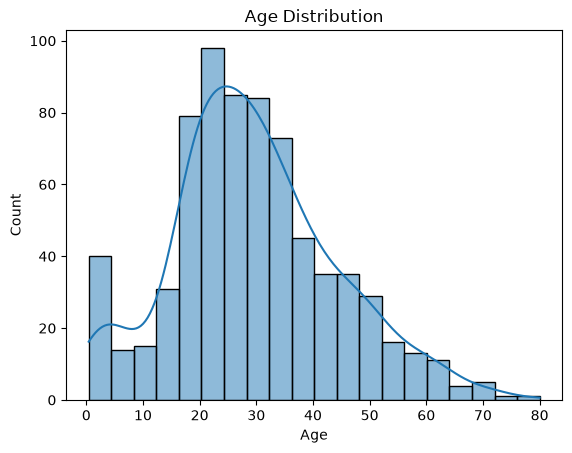

In [6]:
sns.histplot(df["Age"], kde=True)

plt.xlabel("Age")
plt.title("Age Distribution")
plt.show()

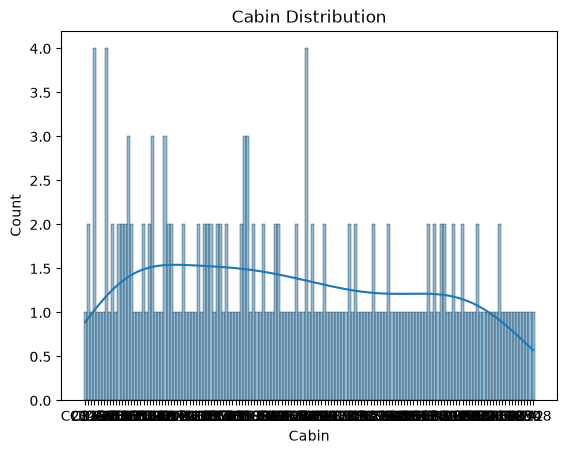

In [7]:
sns.histplot(df["Cabin"], kde=True)

plt.xlabel("Cabin")
plt.title("Cabin Distribution")
plt.show()

### This graph is positive skewed so for fill the  null values of Age column is use median and for normal dis. use mean() and for categorical value column use mode and for time series data use forwardfill , backwardfill 

In [8]:
# Drop unwanted columns
df = df.drop(
    ["PassengerId", "Name", "Ticket", "Cabin", "Embarked"],
    axis=1
)

# Encode Sex
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# Fill missing Age
df["Age"] = df["Age"].fillna(df["Age"].median())

print(df.head())
print(df.isnull().sum())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare
0         0       3    0  22.0      1      0   7.2500
1         1       1    1  38.0      1      0  71.2833
2         1       3    1  26.0      0      0   7.9250
3         1       1    1  35.0      1      0  53.1000
4         0       3    0  35.0      0      0   8.0500
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
dtype: int64


In [9]:
X=df.drop('Survived',axis=1)
y=df['Survived']

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,f1_score,
                            precision_score,
                            recall_score,
                            precision_recall_curve,
                            roc_auc_score,roc_curve,
                            confusion_matrix)

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [12]:
clf1=LogisticRegression()
clf1.fit(X_train,y_train)
y_pred1=clf1.predict(X_test)

In [15]:
clf2=DecisionTreeClassifier()
clf2.fit(X_train,y_train)
y_pred2=clf2.predict(X_test)

In [16]:
print("Accuracy1",accuracy_score(y_test,y_pred1))
print("Accuracy2",accuracy_score(y_test,y_pred2))

Accuracy1 0.8100558659217877
Accuracy2 0.7541899441340782


In [17]:

print("Logistic Regression Confusion Matrix\n")
pd.DataFrame(confusion_matrix(y_test,y_pred1),columns=list(range(0,2)))

Logistic Regression Confusion Matrix



,0,1
0,92,13
1,21,53


In [18]:
print("DecesionTreeClassifire Confusion Matrix\n")
pd.DataFrame(confusion_matrix(y_test,y_pred2),columns=list(range(0,2)))

DecesionTreeClassifire Confusion Matrix



,0,1
0,83,22
1,22,52


In [45]:
print("accuracy1 : ",accuracy_score(y_test,y_pred1))
print("accuracy2 : ",accuracy_score(y_test,y_pred2)) # accuracy=(TP+TN/(TOTAL ELEMENTS))

accuracy1 :  0.8100558659217877
accuracy2 :  0.7541899441340782


In [41]:
print("precision_score1 : ",precision_score(y_test,y_pred1,average='weighted'))
print("precision_score2 : ",precision_score(y_test,y_pred2,average='weighted'))

precision_score1 :  0.8095584809383198
precision_score2 :  0.7541899441340782


In [42]:
print("precision_score1 : ",precision_score(y_test,y_pred1))
print("precision_score2 : ",precision_score(y_test,y_pred2))

precision_score1 :  0.803030303030303
precision_score2 :  0.7027027027027027


In [38]:
print("recall_score1 : ",recall_score(y_test,y_pred1))
print("recall_score2 : ",recall_score(y_test,y_pred2))

recall_score1 :  0.7162162162162162
recall_score2 :  0.7027027027027027


In [33]:
print("f1_score1 : ",f1_score(y_test,y_pred1,average='weighted'))
print("f1_score2 : ",f1_score(y_test,y_pred2,average='weighted'))

f1_score1 :  0.8081141041317352
f1_score2 :  0.7541899441340782


In [46]:
print('roc_auc_score',roc_auc_score(y_test,y_pred1))

roc_auc_score 0.7962033462033462


## **Curve Visulazation For LogisticClassifier**

### This is plot in {0,1} prediction form

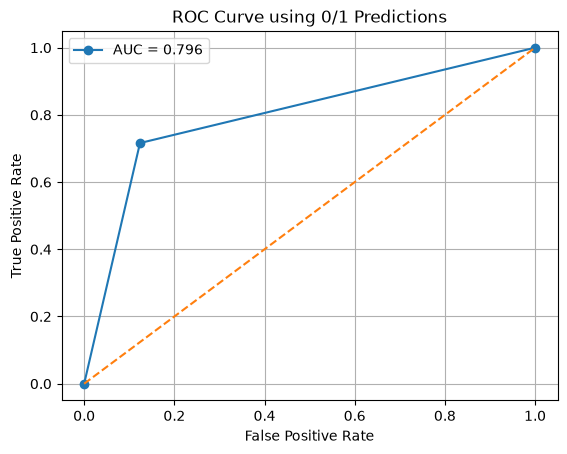

In [52]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred1)
auc = roc_auc_score(y_test, y_pred1)

plt.plot(fpr, tpr, marker="o", label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve using 0/1 Predictions")
plt.legend()
plt.grid()
plt.show()

In [59]:
# Recall= TPR = sensitivity but above recall score for LogisticClassfier =  0.7162162162162162
tpr[1] # which is same above

np.float64(0.7162162162162162)

### This is plot in Probabilites prediction form

ROC-AUC Score: 0.8803088803088803


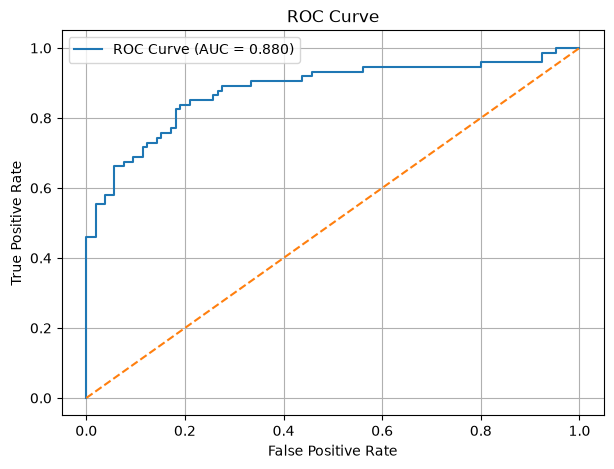

In [49]:
# Probability of class 1 (Survived)
y_prob = clf1.predict_proba(X_test)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)


# AUC
auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", auc)

# Plot
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [50]:
y_pred1

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 1])

In [51]:
y_prob

array([0.0811376 , 0.2371274 , 0.14684498, 0.89847168, 0.67597078,
       0.94059768, 0.64537926, 0.09702826, 0.72635092, 0.92766862,
       0.35468759, 0.07488743, 0.39822631, 0.1114054 , 0.21129152,
       0.94353496, 0.31916315, 0.64544149, 0.26228809, 0.35411211,
       0.13176262, 0.43056293, 0.63794024, 0.14740511, 0.12040664,
       0.07081957, 0.38598206, 0.23868381, 0.0842875 , 0.62358614,
       0.15081614, 0.68729169, 0.48085428, 0.64522207, 0.15495764,
       0.09337949, 0.48497358, 0.64537926, 0.92216097, 0.11802551,
       0.2193964 , 0.08616463, 0.11808064, 0.11797341, 0.49049055,
       0.09671068, 0.15093161, 0.13593758, 0.13143072, 0.2715115 ,
       0.64678241, 0.82546576, 0.04162439, 0.54946393, 0.04010184,
       0.94081707, 0.2314853 , 0.92138818, 0.79450772, 0.70729467,
       0.14288541, 0.87145138, 0.78140482, 0.4767662 , 0.11797341,
       0.65121048, 0.34577395, 0.1147836 , 0.1082667 , 0.83572051,
       0.77057581, 0.94058934, 0.49597259, 0.87293507, 0.13538